In [2]:
#Imports

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns




In [3]:
URL = "https://data.seattle.gov/api/views/65db-xm6k/rows.csv?accessType=DOWNLOAD"
# import du fichier
local_file = "data/fremont.csv"

from pathlib import Path

if Path(local_file).exists():
    print(f"le fichier {local_file} est déjà là")
else:
    print(f"allons chercher le fichier {local_file}")

    import requests
    req = requests.get(URL)

    # doit afficher 200
    print(req.status_code)

    # on sauve tel quel dans le fichier local
    with open(local_file, 'w') as writer:
        writer.write(req.text)

#!head $local_file


le fichier data/fremont.csv est déjà là


In [15]:
#Chargement

# version naïve
data = pd.read_csv(local_file)
data.shape
data.head()



,Date,Fremont Bridge Total,Fremont Bridge East Sidewalk,Fremont Bridge West Sidewalk
0,08/01/2022 12:00:00 AM,23.0,7.0,16.0
1,08/01/2022 01:00:00 AM,12.0,5.0,7.0
2,08/01/2022 02:00:00 AM,3.0,0.0,3.0
3,08/01/2022 03:00:00 AM,5.0,2.0,3.0
4,08/01/2022 04:00:00 AM,10.0,2.0,8.0


In [16]:
#Doublons

!grep '01/01/2014 12:00:00 AM' $local_file

data.drop_duplicates(inplace=True)

data.shape
#On a deux fois moins de lignes

01/01/2014 12:00:00 AM,23,5,18
01/01/2014 12:00:00 AM,23,5,18


(87600, 4)

In [17]:
#Echauffement

sample_dates = pd.to_datetime([
    "2024-01-15 08:00:00",
    "2024-01-20 17:30:00",
    "2024-02-03 12:00:00",
])

#print(type(sample_dates))
# sample_dates est de type pandas.DatatimeIndex

print(sample_dates)

# print(sample_dates.date)
# Ceci renvoie la partie "date" des éléments de temps dans sample_dates
# Les éléments du tableau renvoyé sont des datetime.date

# print(sample_dates.time)
# Renvoie la partie "heure" au format 24h
# Les éléments du tableau renvoyé sont des datetime.time

# print(sample_dates.dayofweek)
# Renvoie des entiers int32 entre 0 et 6 du jour de la semaine

# print(sample_dates.year)
# en int32

DatetimeIndex(['2024-01-15 08:00:00', '2024-01-20 17:30:00',
               '2024-02-03 12:00:00'],
              dtype='datetime64[us]', freq=None)


In [7]:
#Dates après 20 janvier 2024
#On utilise un masque de booléens:



Post20janvier24=sample_dates[sample_dates>=pd.to_datetime("2024-01-20 00:00:00")]
#print(Post20janvier24)

# On a bien les dates après le 20 janvier 2024. Les objets DatetimeIndex peuvent être comparés.

EnJanvier24=sample_dates[sample_dates>=pd.to_datetime("2024-01-01 00:00:00")][sample_dates<=pd.to_datetime("2024-01-31 00:00:00")]
print(EnJanvier24)

DatetimeIndex(['2024-01-15 08:00:00', '2024-01-20 17:30:00'], dtype='datetime64[us]', freq=None)


In [ ]:
#Parser les dates

#data.info()
#data.dtypes

#Transformer la colonne Date en DatetimeIndex

data['Date']=pd.to_datetime(data['Date'])
data.info()
#On a bien converti la colonne Date en format datetime64[us]

data.index=pd.to_datetime(data.Date,format="%m/%d/%Y %I:%M:%S %p")
data.info()

#Là, on a ajouté en tant que colonne spéciale 'index' la colonne Date
#On a donc la colonne 'Date' d'origine
#et la colonne 'Date' dupliquée qui a le statut d'index.
#On supprime la colonne 'Date d'origine et on garde l'index:

del data["Date"]
data.head()

<class 'pandas.DataFrame'>
DatetimeIndex: 87600 entries, 2022-08-01 00:00:00 to 2022-09-30 23:00:00
Data columns (total 3 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Fremont Bridge Total          87586 non-null  float64
 1   Fremont Bridge East Sidewalk  87586 non-null  float64
 2   Fremont Bridge West Sidewalk  87586 non-null  float64
dtypes: float64(3)
memory usage: 2.7 MB
<class 'pandas.DataFrame'>
DatetimeIndex: 87600 entries, 2022-08-01 00:00:00 to 2022-09-30 23:00:00
Data columns (total 3 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Fremont Bridge Total          87586 non-null  float64
 1   Fremont Bridge East Sidewalk  87586 non-null  float64
 2   Fremont Bridge West Sidewalk  87586 non-null  float64
dtypes: float64(3)
memory usage: 2.7 MB


In [ ]:
#Renommons les colonnes avec des noms utilisables

data.columns = ['Total', 'West', 'East']

data.head()



,Total,West,East
Date,,,
2022-08-01 00:00:00,23.0,7.0,16.0
2022-08-01 01:00:00,12.0,5.0,7.0
2022-08-01 02:00:00,3.0,0.0,3.0
2022-08-01 03:00:00,5.0,2.0,3.0
2022-08-01 04:00:00,10.0,2.0,8.0


In [ ]:
#Données manquantes et extension types

LignesIncompletes=data[data.isna().any(axis=1)]
#Le masque de booléens utilisé ici utilise la condition "a au moins une colonne (car axis=1) où l'info est NaN"

LignesIncompletes
#On obtient les 14 lignes contenant au moins un NaN dans une des colonnes (cf data.info précédent, 87586 non-null/87600)
#Le hasard fait qu'ici les lignes qui ont au moins un NaN ont toujours des NaN simultanément sur toute une ligne

,Total,West,East
Date,,,
2013-03-10 02:00:00,NaN,NaN,NaN
2013-06-14 09:00:00,NaN,NaN,NaN
2013-06-14 10:00:00,NaN,NaN,NaN
2014-03-09 02:00:00,NaN,NaN,NaN
2015-03-08 02:00:00,NaN,NaN,NaN
2015-04-21 11:00:00,NaN,NaN,NaN
2015-04-21 12:00:00,NaN,NaN,NaN
2016-03-13 02:00:00,NaN,NaN,NaN
2017-03-12 02:00:00,NaN,NaN,NaN


In [ ]:
#Transformation en entiers

data['Total']=data['Total'].convert_dtypes()
data['West']=data['West'].convert_dtypes()
data['East']=data['East'].convert_dtypes()
data.head()

# Appliquer convert_dtypes() sur data tout entier ne semble pas fonctionner


,Total,West,East
Date,,,
2022-08-01 00:00:00,23,7.0,16.0
2022-08-01 01:00:00,12,5.0,7.0
2022-08-01 02:00:00,3,0.0,3.0
2022-08-01 03:00:00,5,2.0,3.0
2022-08-01 04:00:00,10,2.0,8.0


<Axes: xlabel='Date'>

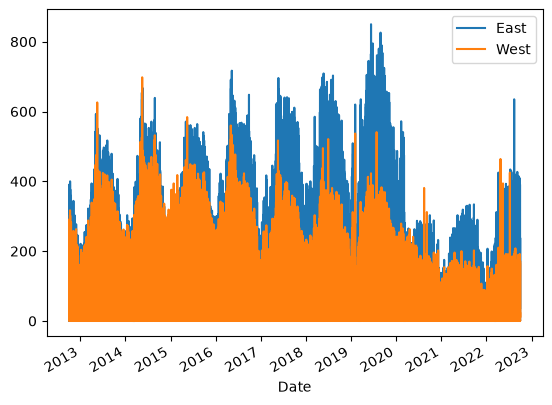

In [34]:
# un premier jet, pas terrible du tout
data[['East', 'West']].plot()


522
87600


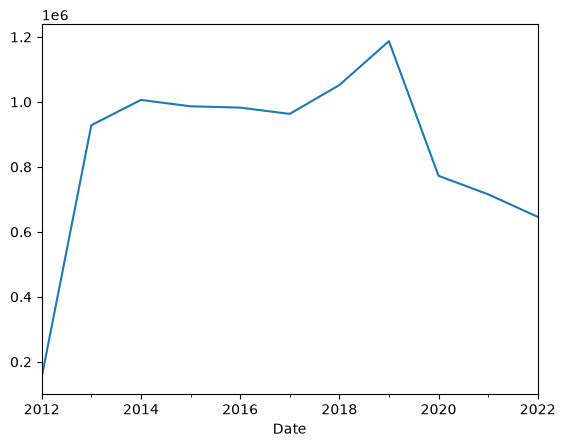

In [ ]:
# Le resample()

# Pour afficher le total de passages agrégé par *année* pour mieux voir l'effet :
data.resample("YE").sum()['Total'].plot()

print(data.resample("1W").sum().shape[0]) #-> 522 lignes quand on agrège par semaine
print(data.shape[0]) #-> au lieu de 87600 par défaut, soit 7*24 fois plus


In [ ]:
# Découpage temporel

dataPre17 = data[data.index.year<=2017]
dataPre17.info

#Je ne sais pas pourquoi West et East sont redevenus en float
dataPre17['West']=dataPre17['West'].convert_dtypes()
dataPre17['East']=dataPre17['East'].convert_dtypes()

dataPre17.info

<bound method DataFrame.info of                      Total  West  East
Date                                  
2012-10-03 00:00:00     13     4     9
2012-10-03 01:00:00     10     4     6
2012-10-03 02:00:00      2     1     1
2012-10-03 03:00:00      5     2     3
2012-10-03 04:00:00      7     6     1
...                    ...   ...   ...
2017-12-31 19:00:00     21     9    12
2017-12-31 20:00:00     14     6     8
2017-12-31 21:00:00     13     3    10
2017-12-31 22:00:00     13     7     6
2017-12-31 23:00:00     16     7     9

[45984 rows x 3 columns]>

(0.0, 2000000.0)

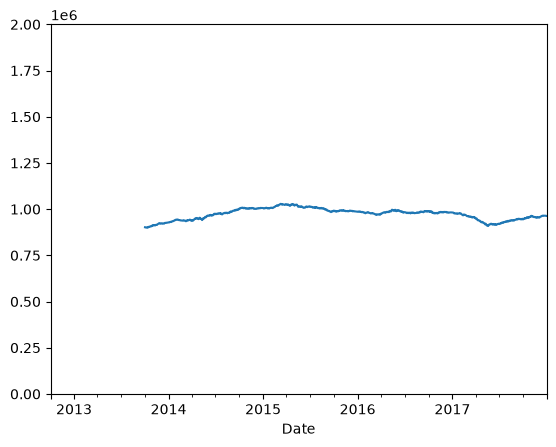

In [ ]:
# Evolution annuelle

# Somme glissante sur 365 jours:

# On commence par agréger par jour, puis avec rolling on fait une sorte de 'groupby' glissant, et on agrège en sommant.
dataPre17.resample("1D").sum().rolling(365).sum()['Total'].plot()
plt.ylim(0,2e6) # Fixation des bornes y
# On a bien lissé la courbe

<Axes: xlabel='time'>

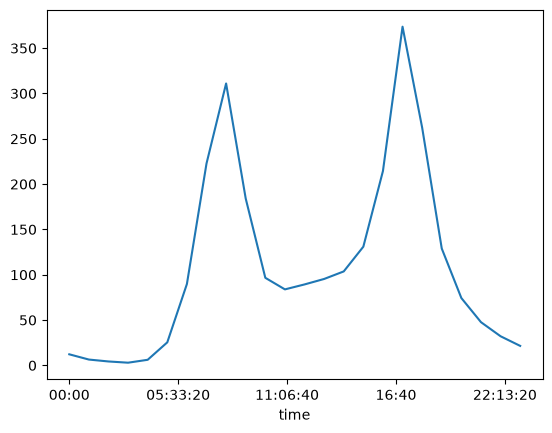

In [68]:
# Profil journalier moyen

dataPre17.groupby(by=dataPre17.index.time).mean()['Total'].plot()

<Axes: xlabel='TimeOnly'>

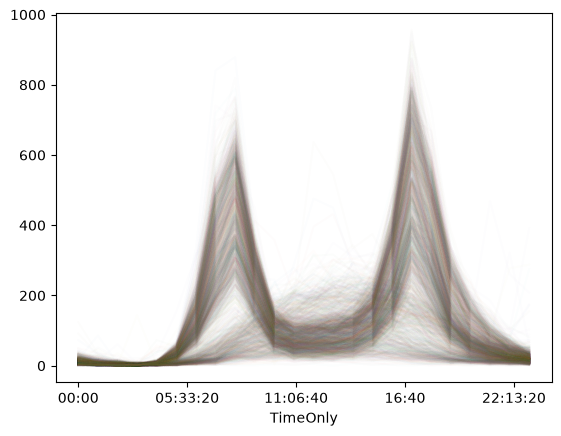

In [72]:
# Une courbe par jour

dataPre17['DateOnly']=dataPre17.index.date
dataPre17['TimeOnly']=dataPre17.index.time
dataPre17.head()
#On a besoin de créer ces colonnes pour les passer en paramètres de pivot

pivoted=dataPre17.pivot(index='TimeOnly',columns='DateOnly',values='Total')

pivoted.plot(legend=None,alpha=0.01)


In [77]:
# Classification des jours

pca_input=pivoted.transpose().fillna(0)
pca_input.head()


TimeOnly,00:00:00,01:00:00,02:00:00,03:00:00,04:00:00,05:00:00,06:00:00,07:00:00,08:00:00,09:00:00,...,14:00:00,15:00:00,16:00:00,17:00:00,18:00:00,19:00:00,20:00:00,21:00:00,22:00:00,23:00:00
DateOnly,,,,,,,,,,,,,,,,,,,,,
2012-10-03,13,10,2,5,7,31,155,352,437,276,...,128,164,315,583,380,128,80,63,49,17
2012-10-04,18,3,9,3,8,26,142,319,418,241,...,119,147,275,507,378,164,83,70,46,41
2012-10-05,11,8,7,4,9,25,105,319,370,212,...,125,164,310,434,316,115,68,42,36,32
2012-10-06,15,15,9,3,5,5,27,33,105,114,...,203,211,183,180,96,78,43,33,34,34
2012-10-07,11,17,3,6,3,9,17,26,69,103,...,241,231,225,191,113,49,55,47,18,16


In [ ]:
# ACP

from scikit.decomposition import PCA

# A l'installation, git bash me dit d'installer scikit-learn au lieu de sklearn.
# Pb: Une fois installé, on ne peut pas écrire de tiret dans from scikit-learn import ...


#pca_input.sklearn.decomposition.PCA(n_components=2)

ModuleNotFoundError: No module named 'scikit'